In [ ]:

import pandas as pd
import numpy as np

# Set random seed
np.random.seed(42)

# Number of records
n = 500

# Generate user type
user_type = np.random.choice(
    ["Student", "Staff"],
    n,
    p=[0.75, 0.25]
)

# Generate complaint categories
categories = ["WiFi", "Software", "Hardware", "Account", "Printer"]

issue_category = np.random.choice(
    categories,
    n,
    p=[0.30, 0.25, 0.20, 0.15, 0.10]
)

# Generate complaint locations
location_options = {
    "WiFi": ["Hostel", "Library", "Classroom"],
    "Software": ["Lab", "Office", "Classroom"],
    "Hardware": ["Lab", "Office"],
    "Account": ["Hostel", "Office", "Library"],
    "Printer": ["Office", "Library", "Lab"]
}

location = [
    np.random.choice(location_options[c])
    for c in issue_category
]

# Generate severity and previous tickets
severity = np.random.randint(1, 6, n)

previous_tickets = np.random.randint(0, 8, n)

# Generate realistic priority scores
category_impact = {
    "WiFi": 0.8,
    "Software": 0.3,
    "Hardware": 1.0,
    "Account": 0.1,
    "Printer": 0.2
}

priority_score = (
    severity * 0.65
    + np.array([
        category_impact[c] for c in issue_category
    ])
    + np.where(previous_tickets >= 4, 0.8, 0)
    + np.random.normal(0, 0.9, n)
)

# Assign complaint priority
priority = np.where(
    priority_score >= 4.2, "High",
    np.where(priority_score >= 2.5, "Medium", "Low")
)

# Generate resolution time
base_time = {
    "WiFi": 2.5,
    "Software": 3.0,
    "Hardware": 5.0,
    "Account": 1.5,
    "Printer": 2.0
}

resolution_time_hours = np.array([
    base_time[c] + s * 0.55 + p * 0.15
    for c, s, p in zip(
        issue_category, severity, previous_tickets
    )
])

resolution_time_hours += np.random.normal(0, 0.8, n)

resolution_time_hours = np.maximum(
    0.5, resolution_time_hours
)

# Create final dataset
df = pd.DataFrame({
    "ticket_no.": range(1001, 1001 + n),
    "user_type": user_type,
    "issue_category": issue_category,
    "location": location,
    "severity": severity,
    "previous_tickets": previous_tickets,
    "priority": priority,
    "resolution_time_hours": np.round(
        resolution_time_hours, 2
    )
})

# Save dataset
df.to_csv("IT_Helpdesk_Dataset.csv", index=False)

# Display dataset information
print("Dataset created successfully!")

print("\nFirst 10 records:")
print(df.head(10))

print("\nDataset shape:")
print(df.shape)

print("\nUser type distribution:")
print(df["user_type"].value_counts())

print("\nIssue category distribution:")
print(df["issue_category"].value_counts())

print("\nPriority distribution:")
print(df["priority"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nAverage resolution time:")
print(df["resolution_time_hours"].mean())

print("\nCSV file saved successfully!")


Dataset created successfully!

First 10 records:
   ticket_no. user_type issue_category   location  severity  previous_tickets  \
0        1001   Student       Hardware        Lab         1                 1   
1        1002     Staff       Software     Office         4                 4   
2        1003   Student       Software  Classroom         2                 3   
3        1004   Student        Account    Library         3                 6   
4        1005   Student       Hardware        Lab         2                 5   
5        1006   Student           WiFi     Hostel         4                 7   
6        1007   Student        Printer        Lab         4                 4   
7        1008     Staff        Account     Hostel         5                 2   
8        1009   Student        Printer    Library         1                 5   
9        1010   Student       Hardware     Office         5                 1   

  priority  resolution_time_hours  
0      Low             

In [ ]:

# Import libraries

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset

df = pd.read_csv("IT_Helpdesk_Dataset.csv")

# Select input and output variables

X = df[
    ["user_type", "issue_category", "severity",
     "previous_tickets"]
]

y = df["resolution_time_hours"]

# Preprocess categorical columns

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["user_type", "issue_category"])
    ],
    remainder="passthrough"
)

# Create Linear Regression model

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model

model.fit(X_train, y_train)

# Predict resolution time

y_pred = model.predict(X_test)

# Evaluate the model

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")

print("Mean Absolute Error:", round(mae, 2))

print("Mean Squared Error:", round(mse, 2))

print("R2 Score:", round(r2, 4))

# Display actual and predicted values

results = pd.DataFrame({
    "Actual Time": y_test.values,
    "Predicted Time": y_pred.round(2)
})

print("\nSample Predictions:")
print(results.head(10))


Linear Regression Results
Mean Absolute Error: 0.58
Mean Squared Error: 0.48
R2 Score: 0.8357

Sample Predictions:
   Actual Time  Predicted Time
0         5.91            5.45
1         7.24            7.16
2         2.90            3.90
3         5.32            5.03
4         3.63            3.63
5         5.40            6.38
6         4.54            5.88
7         7.24            7.26
8         4.14            4.48
9         9.35            8.98


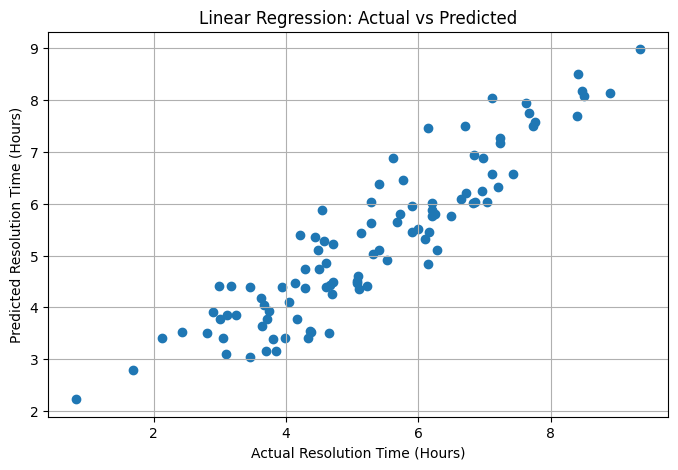

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Resolution Time (Hours)")
plt.ylabel("Predicted Resolution Time (Hours)")

plt.title("Linear Regression: Actual vs Predicted")

plt.grid(True)

plt.show()


ANN Classification Results
Accuracy: 54.0 %

Classification Report:
              precision    recall  f1-score   support

     Account       0.25      0.08      0.12        13
    Hardware       0.41      0.60      0.49        20
     Printer       1.00      0.11      0.20         9
    Software       0.53      0.32      0.40        25
        WiFi       0.63      0.97      0.76        33

    accuracy                           0.54       100
   macro avg       0.56      0.42      0.39       100
weighted avg       0.55      0.54      0.48       100



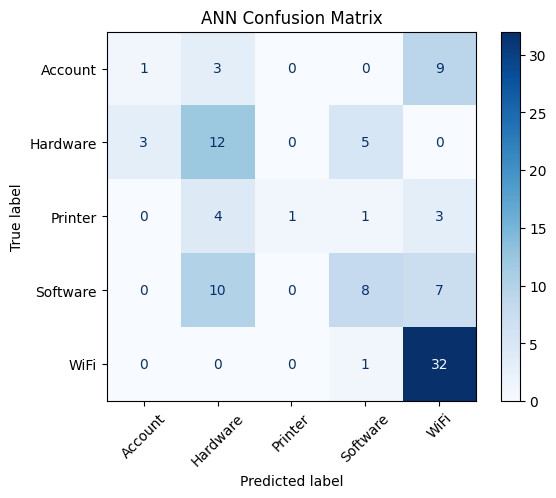

In [ ]:

# Import required libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset

df = pd.read_csv("IT_Helpdesk_Dataset.csv")

# Select input and output variables

X = df[
    ["user_type", "location", "severity",
     "previous_tickets"]
]

y = df["issue_category"]

# Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["user_type", "location"]),

        ("num", StandardScaler(),
         ["severity", "previous_tickets"])
    ]
)

# Create ANN model

ann_model = Pipeline([
    ("preprocessor", preprocessor),

    ("ann", MLPClassifier(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    ))
])

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train ANN

ann_model.fit(X_train, y_train)

# Make predictions

y_pred = ann_model.predict(X_test)

# Evaluate model

accuracy = accuracy_score(y_test, y_pred)

print("ANN Classification Results")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

# Confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=ann_model.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ann_model.classes_
)

display.plot(cmap="Blues", xticks_rotation=45)

plt.title("ANN Confusion Matrix")

plt.show()


Decision Tree Accuracy: 0.58

Classification Report:

              precision    recall  f1-score   support

        High       0.46      0.33      0.39        18
         Low       0.71      0.50      0.59        34
      Medium       0.56      0.73      0.63        48

    accuracy                           0.58       100
   macro avg       0.58      0.52      0.53       100
weighted avg       0.59      0.58      0.57       100



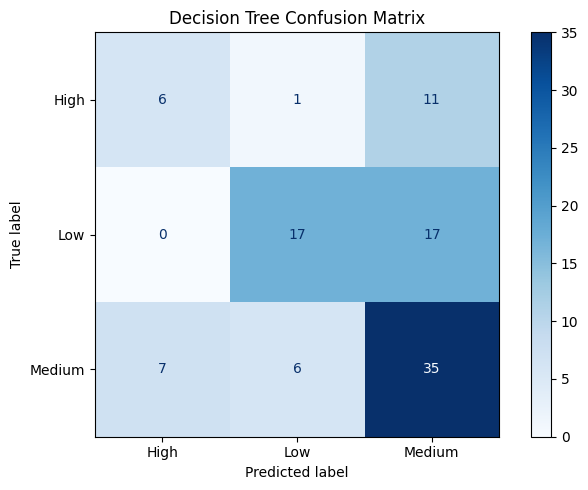

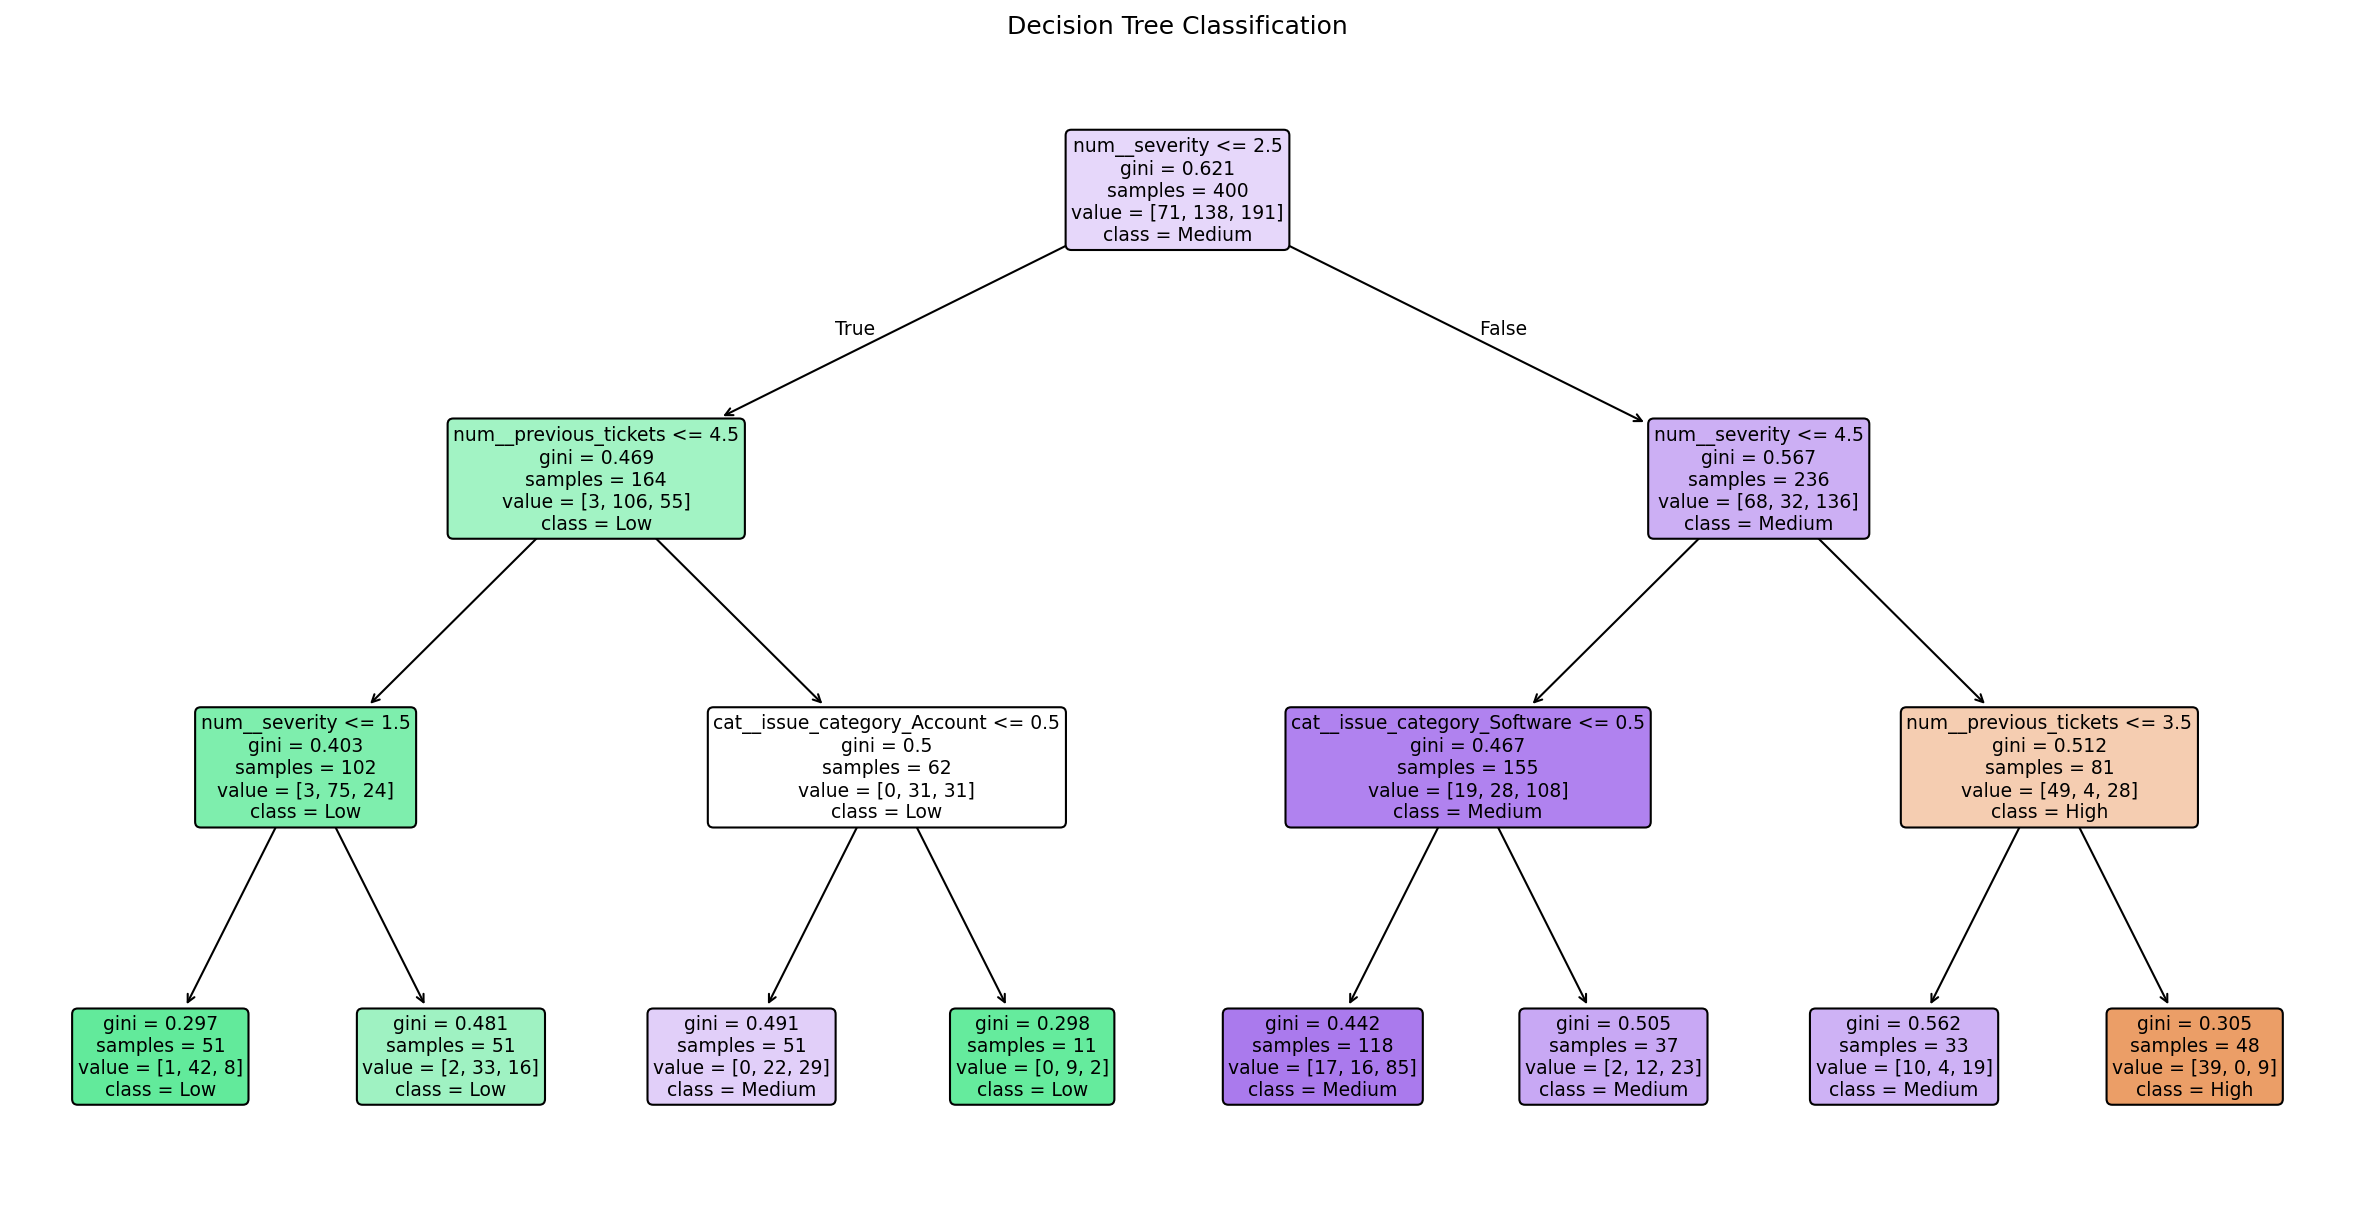

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Select input and output columns
X = df[['user_type', 'issue_category', 'severity', 'previous_tickets']]
y = df['priority']

# Identify categorical and numerical columns
categorical_features = ['user_type', 'issue_category']
numerical_features = ['severity', 'previous_tickets']

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

# Create Decision Tree model
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=3,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred = dt_model.predict(X_test)

# Model evaluation
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dt_model.classes_
)

disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=True
)

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.savefig("Decision_Tree_Confusion_Matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Get feature names
feature_names = dt_model.named_steps['preprocessor'].get_feature_names_out()

# Plot Decision Tree (unchanged settings)
plt.figure(figsize=(20, 10), dpi=150)

plot_tree(
    dt_model.named_steps['classifier'],
    feature_names=feature_names,
    class_names=dt_model.named_steps['classifier'].classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classification")
plt.savefig("Decision_Tree.png", dpi=300, bbox_inches="tight")
plt.show()

K-means Clustering Results

Number of Clusters: 3
Silhouette Score: 0.3194

Cluster Distribution:
cluster
0    204
1    151
2    145
Name: count, dtype: int64

Cluster Analysis:
         severity  previous_tickets  resolution_time_hours
cluster                                                   
0            1.66              3.81                   3.87
1            3.92              1.56                   5.51
2            4.06              5.59                   6.65


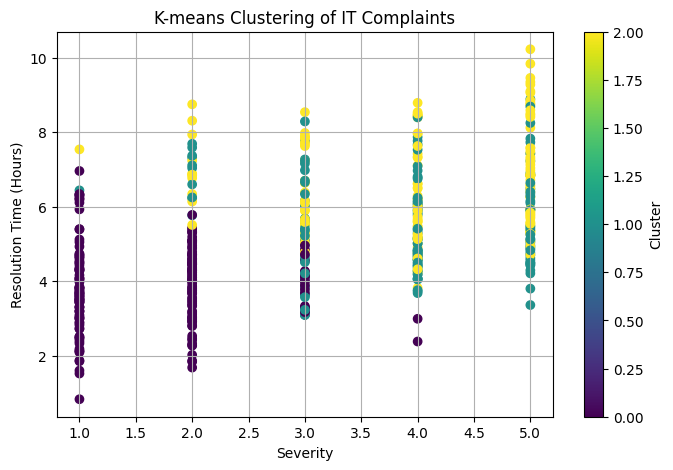

In [ ]:

# Import required libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load dataset

df = pd.read_csv("IT_Helpdesk_Dataset.csv")

# Select features for clustering

X = df[
    ["severity", "previous_tickets",
     "resolution_time_hours"]
]

# Scale the data

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Create K-means model

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters

df["cluster"] = kmeans.fit_predict(X_scaled)

# Calculate silhouette score

score = silhouette_score(X_scaled, df["cluster"])

print("K-means Clustering Results")

print("\nNumber of Clusters:", 3)

print("Silhouette Score:", round(score, 4))

# Display number of complaints in each cluster

print("\nCluster Distribution:")

print(df["cluster"].value_counts().sort_index())

# Display average characteristics of each cluster

print("\nCluster Analysis:")

print(
    df.groupby("cluster")[
        ["severity", "previous_tickets",
         "resolution_time_hours"]
    ].mean().round(2)
)

# Visualize clusters

plt.figure(figsize=(8, 5))

plt.scatter(
    df["severity"],
    df["resolution_time_hours"],
    c=df["cluster"],
    cmap="viridis"
)

plt.xlabel("Severity")

plt.ylabel("Resolution Time (Hours)")

plt.title("K-means Clustering of IT Complaints")

plt.colorbar(label="Cluster")

plt.grid(True)

plt.show()
